# Atividade 2 – Quantos centros de retirada construir? (Análise de conglomerados)
**Melhores Compras – Fase 6 | Grupo 86**

**Problema:** a logística nos enviou uma amostra de locais onde houve **falha na entrega** (latitude, longitude e valor da entrega).
Precisamos estimar **quantos centros de retirada** construir e **quanto em valor de entregas** cada um passaria a atender.

**Abordagem:** análise de conglomerados (clusterização) sobre a **posição** dos pontos. Cada grupo formado representa a área de um centro;
somamos o valor das entregas de cada grupo.

**Roteiro**
1. Carga e tratamento da base (sem alterar o arquivo original – todos os tratamentos estão neste código)
2. Escolha do número de centros (k) com métricas objetivas
3. Escolha do algoritmo de clusterização
4. Modelo final e valor total das entregas por centro
5. Conclusão

In [1]:
# Bibliotecas
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

SEED = 42                      # semente fixa: o resultado é reprodutível
np.random.seed(SEED)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

## 1. Carga e tratamento da base
O arquivo **não é alterado**: ele é apenas lido. Todos os tratamentos acontecem em uma *cópia* em memória (`df`).

Cuidado com o formato: o CSV usa **vírgula como separador decimal** (ex.: `"-21,591360"`), por isso a leitura com `decimal=','`.

In [2]:
# Localiza o CSV fornecido (mesma pasta do notebook, /content do Colab ou Google Drive)
padroes = ['*Geolocaliza*.csv', '/content/*Geolocaliza*.csv', '/content/drive/MyDrive/*Geolocaliza*.csv']
achados = [f for p in padroes for f in glob.glob(p)]

if not achados:
    try:                                   # no Colab, abre o seletor de upload
        from google.colab import files
        files.upload()
        achados = glob.glob('*Geolocaliza*.csv')
    except ImportError:
        pass
if not achados:
    raise FileNotFoundError('Coloque o CSV da logística na mesma pasta do notebook.')

ARQUIVO = achados[0]
print('Arquivo lido:', os.path.basename(ARQUIVO))

# Leitura (somente leitura do arquivo original). decimal=',' converte "-21,591360" em -21.591360
bruto = pd.read_csv(ARQUIVO, decimal=',')
print('Formato:', bruto.shape)
bruto.head()

Arquivo lido: Fiap_On_-_Fase_6_-_Geolocaliza__o_Dataset_-_Asset.csv
Formato: (653, 3)


,latitude,longitude,price
0,-21.59,-51.07,52.47
1,-21.29,-49.65,37.03
2,-22.03,-47.07,71.50
3,-21.92,-46.69,88.27
4,-22.48,-46.63,36.16


In [3]:
# Diagnóstico de qualidade da base
print('Tipos:\n', bruto.dtypes, '\n')
print('Valores nulos por coluna:\n', bruto.isna().sum(), '\n')
print('Linhas totalmente duplicadas:', bruto.duplicated().sum())
print('Pontos com a mesma coordenada:', bruto.duplicated(['latitude', 'longitude']).sum(), '\n')
print(bruto.describe().T)

# Outliers pela regra do IQR (apenas diagnóstico)
print('\nOutliers (regra 1,5 x IQR):')
for c in bruto.columns:
    q1, q3 = bruto[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((bruto[c] < q1 - 1.5 * iqr) | (bruto[c] > q3 + 1.5 * iqr)).sum()
    print(f'  {c:>9}: {n}')

Tipos:
 latitude     float64
longitude    float64
price        float64
dtype: object 

Valores nulos por coluna:
 latitude     0
longitude    0
price        0
dtype: int64 

Linhas totalmente duplicadas: 0
Pontos com a mesma coordenada: 0 

           count   mean   std    min    25%    50%    75%    max
latitude  653.00 -22.15  1.18 -25.01 -23.06 -22.21 -21.18 -19.92
longitude 653.00 -48.64  1.74 -52.82 -50.04 -48.62 -47.29 -44.33
price     653.00  63.07 28.20  12.12  39.16  65.02  85.89 111.71

Outliers (regra 1,5 x IQR):
   latitude: 0
  longitude: 0
      price: 0


In [4]:
# Tratamentos aplicados em uma CÓPIA (o arquivo original permanece intacto)
df = bruto.copy()
n0 = len(df)

df = df.dropna()                                   # 1) remove linhas com valor ausente
df = df.drop_duplicates()                          # 2) remove linhas repetidas
df = df[df['price'] > 0]                           # 3) valor de entrega precisa ser positivo
df = df[df['latitude'].between(-90, 90) & df['longitude'].between(-180, 180)]   # 4) coordenadas válidas
df = df.reset_index(drop=True)

print(f'Linhas antes: {n0} | depois: {len(df)} | removidas: {n0 - len(df)}')
print(f'Valor total das entregas na base tratada: R$ {df.price.sum():,.2f}')

Linhas antes: 653 | depois: 653 | removidas: 0
Valor total das entregas na base tratada: R$ 41,183.81


**O que o diagnóstico mostrou:** a base já veio limpa – sem nulos, sem duplicatas e sem outliers (por IQR) – então os tratamentos acima
não removeram nenhuma linha, mas ficam no código para garantir a qualidade se a base for atualizada.

**Decisões de modelagem**
- **Variáveis usadas no agrupamento: apenas `latitude` e `longitude`.** Queremos agrupar por *proximidade*. O valor da entrega (`price`) **não** entra
  no agrupamento (senão misturaríamos "perto" com "caro"); ele é usado depois, só para somar o valor de cada grupo.
- **As coordenadas não são reais** (orientação do enunciado). Por isso tratamos os pontos como posições num plano: distância **euclidiana simples**,
  sem fórmula de distância geográfica (haversine) e sem mapa de fundo. As duas colunas estão na mesma unidade (graus), então mantemos a escala original –
  a seção 3 mostra por que padronizar não é desejável aqui.

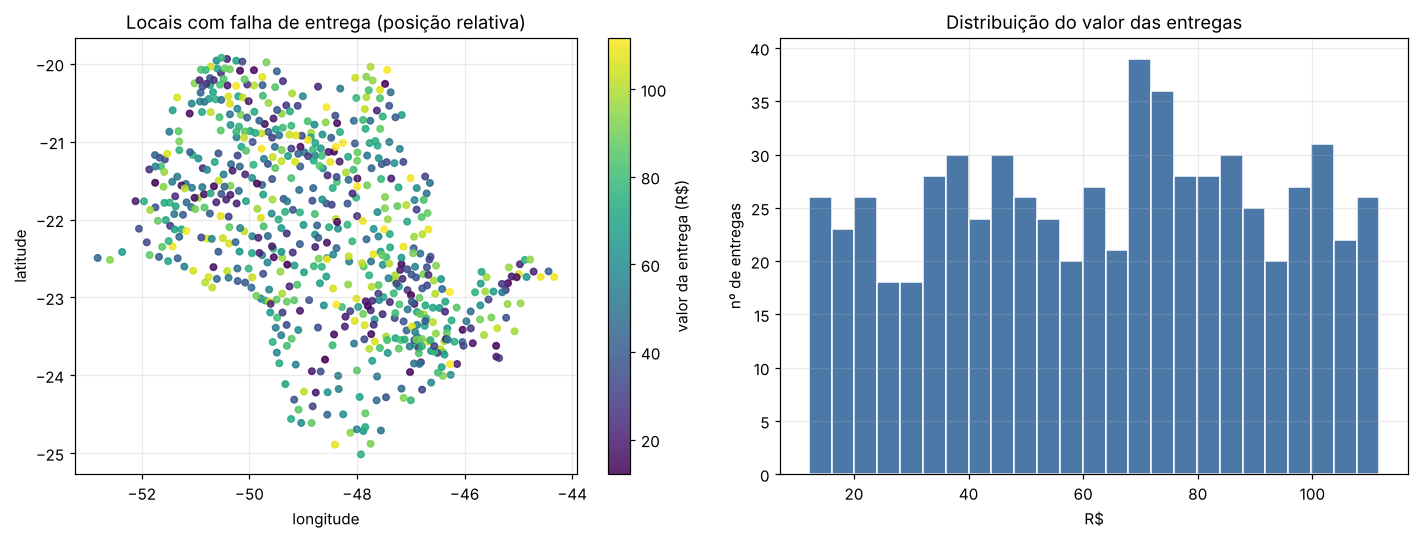

In [5]:
# Visão geral dos pontos e do valor das entregas
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sc = ax[0].scatter(df.longitude, df.latitude, c=df.price, cmap='viridis', s=18, alpha=.85)
plt.colorbar(sc, ax=ax[0], label='valor da entrega (R$)')
ax[0].set(title='Locais com falha de entrega (posição relativa)', xlabel='longitude', ylabel='latitude')
ax[1].hist(df.price, bins=25, color='#4C78A8', edgecolor='white')
ax[1].set(title='Distribuição do valor das entregas', xlabel='R$', ylabel='nº de entregas')
plt.tight_layout(); plt.show()

> **Leitura do gráfico:** os pontos se espalham de forma **contínua** pela região, sem "ilhas" isoladas muito claras.
> Isso já antecipa que o número de centros não será "óbvio" a olho nu – precisaremos de métricas para apoiar a decisão.

## 2. Quantos centros? Escolha do k
Testamos de 2 a 15 grupos com o K-Means e olhamos quatro sinais:

| Métrica | O que mede | Melhor |
|---|---|---|
| **Inércia (cotovelo)** | quão perto os pontos estão do centro do seu grupo | queda que "achata" (cotovelo) |
| **Silhueta** | quão bem separado e coeso é cada grupo (−1 a 1) | maior |
| **Davies-Bouldin** | sobreposição entre grupos | menor |
| **Estabilidade** | se o agrupamento se repete ao reamostrar a base (ARI, 0 a 1) | maior |

A estabilidade importa para o negócio: não queremos escolher locais de centros que mudariam muito com uma amostra um pouco diferente.

In [6]:
X = df[['latitude', 'longitude']].values       # somente a posição entra no agrupamento
K_RANGE = range(2, 16)
B = 30                                          # nº de reamostragens para medir a estabilidade
rng = np.random.default_rng(SEED)

linhas = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    # Estabilidade: reajusta o modelo em amostras com reposição (bootstrap) e compara com o agrupamento original
    aris = []
    for b in range(B):
        idx = rng.choice(len(X), len(X), replace=True)
        mb = KMeans(n_clusters=k, n_init=10, random_state=b).fit(X[idx])
        aris.append(adjusted_rand_score(km.labels_, mb.predict(X)))
    linhas.append({'k': k, 'inércia': km.inertia_,
                   'silhueta': silhouette_score(X, km.labels_),
                   'davies_bouldin': davies_bouldin_score(X, km.labels_),
                   'calinski_harabasz': calinski_harabasz_score(X, km.labels_),
                   'estabilidade (ARI)': np.mean(aris)})
metricas = pd.DataFrame(linhas).set_index('k')
metricas.round(3)

,inércia,silhueta,davies_bouldin,calinski_harabasz,estabilidade (ARI)
k,,,,,
2,"1,236.28",0.47,0.79,860.38,0.94
3,865.26,0.39,0.97,753.07,0.87
4,630.75,0.41,0.81,768.07,0.87
5,502.88,0.40,0.87,762.61,0.88
6,411.09,0.39,0.79,774.05,0.81
7,341.31,0.40,0.80,797.73,0.78
8,291.49,0.40,0.78,815.15,0.78
9,255.49,0.39,0.77,823.85,0.80
10,227.97,0.38,0.81,828.17,0.73


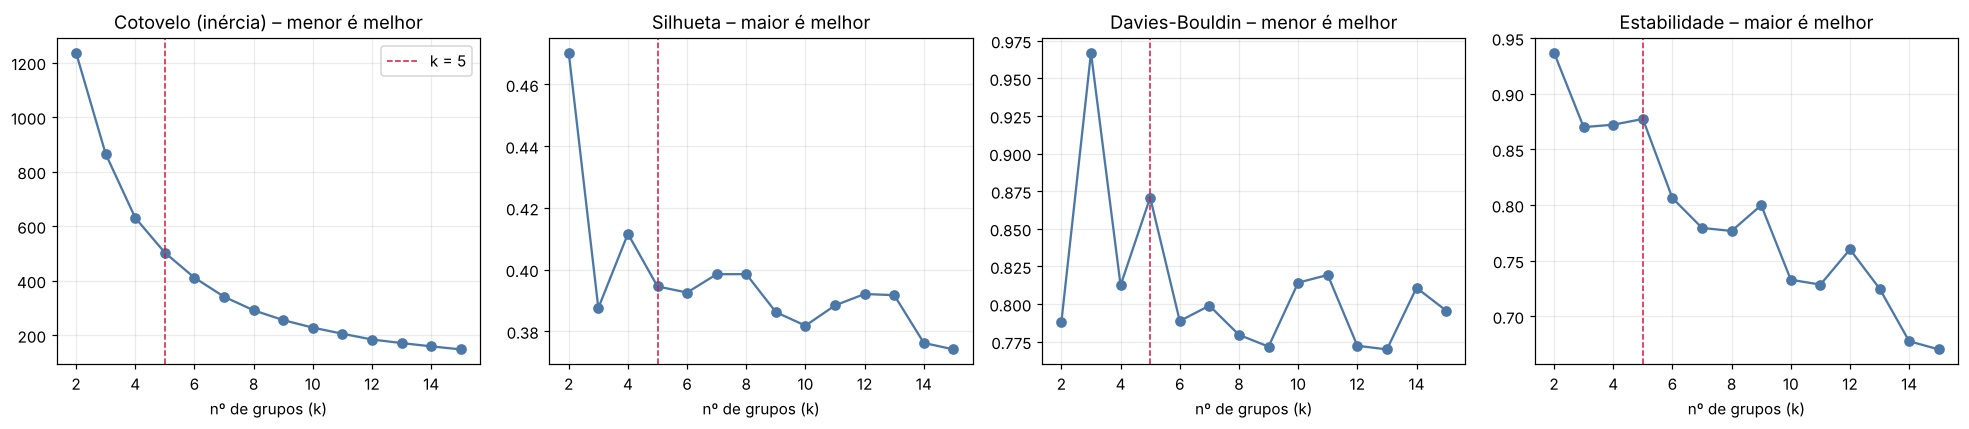

Distância à reta (quanto maior, mais "cotovelo"):
k
2    0.00
3    0.26
4    0.40
5    0.44
6    0.45
7    0.44
8    0.41
9    0.36
10   0.31
11   0.26
12   0.20
13   0.13
14   0.07
15   0.00

k do cotovelo: 6


In [7]:
# Gráficos das métricas
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, col, tit in zip(ax, ['inércia', 'silhueta', 'davies_bouldin', 'estabilidade (ARI)'],
                       ['Cotovelo (inércia) – menor é melhor', 'Silhueta – maior é melhor',
                        'Davies-Bouldin – menor é melhor', 'Estabilidade – maior é melhor']):
    a.plot(metricas.index, metricas[col], marker='o', color='#4C78A8')
    a.axvline(5, color='crimson', ls='--', lw=1, label='k = 5')
    a.set(title=tit, xlabel='nº de grupos (k)'); a.set_xticks(list(K_RANGE)[::2])
ax[0].legend()
plt.tight_layout(); plt.show()

# Cotovelo objetivo: ponto da curva mais distante da reta que liga o primeiro ao último ponto (método "kneedle" simplificado)
x = (metricas.index - metricas.index.min()) / (metricas.index.max() - metricas.index.min())
y = (metricas['inércia'] - metricas['inércia'].min()) / (metricas['inércia'].max() - metricas['inércia'].min())
dist = (1 - x) - y
dist = pd.Series(np.asarray(dist), index=metricas.index)
print('Distância à reta (quanto maior, mais "cotovelo"):')
print(dist.round(3).to_string())
print('\nk do cotovelo:', int(dist.idxmax()))

In [8]:
# Equilíbrio entre os grupos: tamanho e participação no valor total, para k de 3 a 8
res = []
for k in range(3, 9):
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    s = df.assign(g=km.labels_).groupby('g')['price'].agg(['count', 'sum'])
    res.append({'k': k, 'menor grupo (nº entregas)': s['count'].min(), 'maior grupo (nº entregas)': s['count'].max(),
                'menor grupo (% do valor)': 100 * s['sum'].min() / s['sum'].sum(),
                'maior grupo (% do valor)': 100 * s['sum'].max() / s['sum'].sum()})
pd.DataFrame(res).set_index('k').round(1)

,menor grupo (nº entregas),maior grupo (nº entregas),menor grupo (% do valor),maior grupo (% do valor)
k,,,,
3,208,234,31.10,35.50
4,126,207,19.00,31.20
5,114,162,17.00,24.90
6,47,158,6.90,25.00
7,43,140,6.20,21.80
8,39,110,5.80,16.70


### Decisão: k = 5 centros

**Como ler as métricas acima**
- **k = 2 tem a melhor silhueta (0,47) e a maior estabilidade (0,94), mas é uma divisão grosseira:** basicamente uma metade para cada lado (cerca de 50% do valor em cada). Com tão poucos centros, o cliente continuaria longe do box, o que não ataca o problema da entrega. Quando os pontos não formam "ilhas", silhueta e estabilidade favorecem naturalmente poucos grupos, por isso não usamos k = 2.
- **De k = 3 em diante as métricas ficam praticamente empatadas** (silhueta entre 0,37 e 0,41; Davies-Bouldin entre 0,77 e 0,97). Ou seja, a base **não tem um número "natural" de grupos**: os pontos formam uma nuvem contínua. A escolha de k combina estatística com critério de negócio.
- **Cotovelo:** a curva de inércia dobra em torno de k = 5 e k = 6 (distância à reta de 0,44 e 0,45, praticamente iguais).
- **Estabilidade:** k = 5 é o mais estável entre os k ≥ 3 (ARI 0,88). De k = 6 em diante cai para a faixa de 0,67 a 0,81, ou seja, os grupos passam a mudar conforme a amostra.
- **Equilíbrio:** com k = 5 cada centro atende entre 114 e 162 entregas (17,0% a 24,9% do valor). Com k = 6 surge um centro com só 47 entregas (6,9% do valor), difícil de justificar como investimento.

**Escolha: k = 5.** Está na região do cotovelo, é o mais estável e deixa os centros com cargas parecidas. Na seção 4 mostramos também o que muda com 4 ou 6 centros.

## 3. Escolha do algoritmo
Comparamos o K-Means com outras três técnicas, todas com k = 5 (quando aplicável), usando o mesmo conjunto de pontos.

In [9]:
K = 5

# 3.1 Padronizar mudaria o resultado? (as duas colunas já estão em graus)
Xp = StandardScaler().fit_transform(X)
lab_raw = KMeans(K, n_init=50, random_state=SEED).fit_predict(X)
lab_pad = KMeans(K, n_init=50, random_state=SEED).fit_predict(Xp)
print(f'Concordância (ARI) entre agrupar com e sem padronização: {adjusted_rand_score(lab_raw, lab_pad):.3f}  (1 = idêntico)\n')

# 3.2 K-Means x Hierárquico (Ward) x Mistura Gaussiana
modelos = {
    'K-Means':               lab_raw,
    'Hierárquico (Ward)':    AgglomerativeClustering(K, linkage='ward').fit_predict(X),
    'Mistura Gaussiana':     GaussianMixture(K, covariance_type='full', n_init=10, random_state=SEED).fit_predict(X),
}
comp = pd.DataFrame({nome: {'silhueta': silhouette_score(X, l), 'Davies-Bouldin': davies_bouldin_score(X, l),
                            'menor grupo': np.bincount(l).min(), 'maior grupo': np.bincount(l).max(),
                            'ARI vs K-Means': adjusted_rand_score(lab_raw, l)}
                     for nome, l in modelos.items()}).T
print(comp.round(3).to_string())

# 3.3 DBSCAN (não exige k, mas depende de eps/min_samples) – varredura de eps
print('\nDBSCAN (min_samples = 5):')
for eps in [0.1, 0.2, 0.3, 0.5, 0.8]:
    l = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    n_g = len(set(l)) - (1 if -1 in l else 0)
    print(f'  eps = {eps:.1f} -> {n_g:>2} grupos | {np.sum(l == -1):>3} pontos sem grupo (ruído)')

Concordância (ARI) entre agrupar com e sem padronização: 0.805  (1 = idêntico)



                    silhueta  Davies-Bouldin  menor grupo  maior grupo  ARI vs K-Means
K-Means                 0.40            0.87       114.00       162.00            1.00
Hierárquico (Ward)      0.34            0.82        66.00       240.00            0.51
Mistura Gaussiana       0.36            0.88        71.00       179.00            0.46

DBSCAN (min_samples = 5):
  eps = 0.1 ->  1 grupos | 640 pontos sem grupo (ruído)
  eps = 0.2 -> 18 grupos | 174 pontos sem grupo (ruído)
  eps = 0.3 ->  3 grupos |  12 pontos sem grupo (ruído)
  eps = 0.5 ->  1 grupos |   0 pontos sem grupo (ruído)
  eps = 0.8 ->  1 grupos |   0 pontos sem grupo (ruído)


### Por que o K-Means
- **Entrega o que o negócio precisa:** cada grupo tem um **centroide** (a posição média das entregas do grupo), que serve como ponto candidato para o centro de retirada. O hierárquico e o DBSCAN não geram um "centro" natural.
- **Responde à pergunta "quantos?":** o K-Means recebe k como parâmetro, então conseguimos comparar cenários (seção 2) e simular 4, 5 ou 6 centros.
- **Grupos compactos e equilibrados:** com k = 5 teve a melhor silhueta (0,40, contra 0,36 da Mistura Gaussiana e 0,34 do Ward) e os tamanhos mais parecidos (114 a 162 entregas, contra 66 a 240 no Ward e 71 a 179 na Mistura Gaussiana). Centros com cargas parecidas facilitam padronizar o tamanho dos boxes.
- **O DBSCAN não se adequa:** como não há regiões densas bem separadas, o resultado depende totalmente do parâmetro eps (1, 18, 3 e 1 grupos conforme eps muda de 0,1 a 0,5) e ele deixa pontos "sem grupo" (ruído). Toda entrega com falha precisa ser atendida por algum centro.
- **Sem padronização:** as duas variáveis já estão na mesma unidade (graus). Padronizar esticaria a latitude em relação à longitude, distorcendo as distâncias, e mudaria o agrupamento (ARI = 0,81 em relação ao original). Mantivemos a escala original.

## 4. Modelo final: K-Means com 5 centros
Ajustamos o modelo final, numeramos os centros de **oeste para leste** (para a numeração ser estável) e somamos o valor das entregas de cada grupo.

In [10]:
modelo = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(X)

# Renumera os grupos pela longitude do centro (oeste -> leste): Centro 1, 2, ...
ordem = np.argsort(modelo.cluster_centers_[:, 1])
mapa = {antigo: novo + 1 for novo, antigo in enumerate(ordem)}
df['centro'] = [f'Centro {mapa[l]}' for l in modelo.labels_]

centros = pd.DataFrame(modelo.cluster_centers_[ordem], columns=['latitude', 'longitude'],
                       index=[f'Centro {i}' for i in range(1, K + 1)])

# Valor total das entregas por centro
tabela = (df.groupby('centro')['price']
            .agg(**{'nº de entregas': 'count', 'valor total (R$)': 'sum', 'ticket médio (R$)': 'mean'}))
tabela['% do valor total'] = 100 * tabela['valor total (R$)'] / tabela['valor total (R$)'].sum()
tabela = tabela.join(centros.rename(columns={'latitude': 'lat. do centro', 'longitude': 'long. do centro'}))

# Conferência: nenhuma entrega ficou de fora nem foi contada duas vezes
assert tabela['nº de entregas'].sum() == len(df)
assert np.isclose(tabela['valor total (R$)'].sum(), df['price'].sum())

total = pd.DataFrame({'nº de entregas': [tabela['nº de entregas'].sum()],
                      'valor total (R$)': [tabela['valor total (R$)'].sum()],
                      'ticket médio (R$)': [df.price.mean()], '% do valor total': [100.0]}, index=['TOTAL'])
pd.concat([tabela, total]).round(3)

,nº de entregas,valor total (R$),ticket médio (R$),% do valor total,lat. do centro,long. do centro
Centro 1,114,"7,020.18",61.58,17.05,-21.95,-50.96
Centro 2,124,"7,794.24",62.86,18.93,-20.72,-50.03
Centro 3,124,"7,660.93",61.78,18.60,-23.32,-48.62
Centro 4,129,"8,461.52",65.59,20.55,-21.30,-48.00
Centro 5,162,"10,246.94",63.25,24.88,-23.18,-46.45
TOTAL,653,"41,183.81",63.07,100.00,NaN,NaN


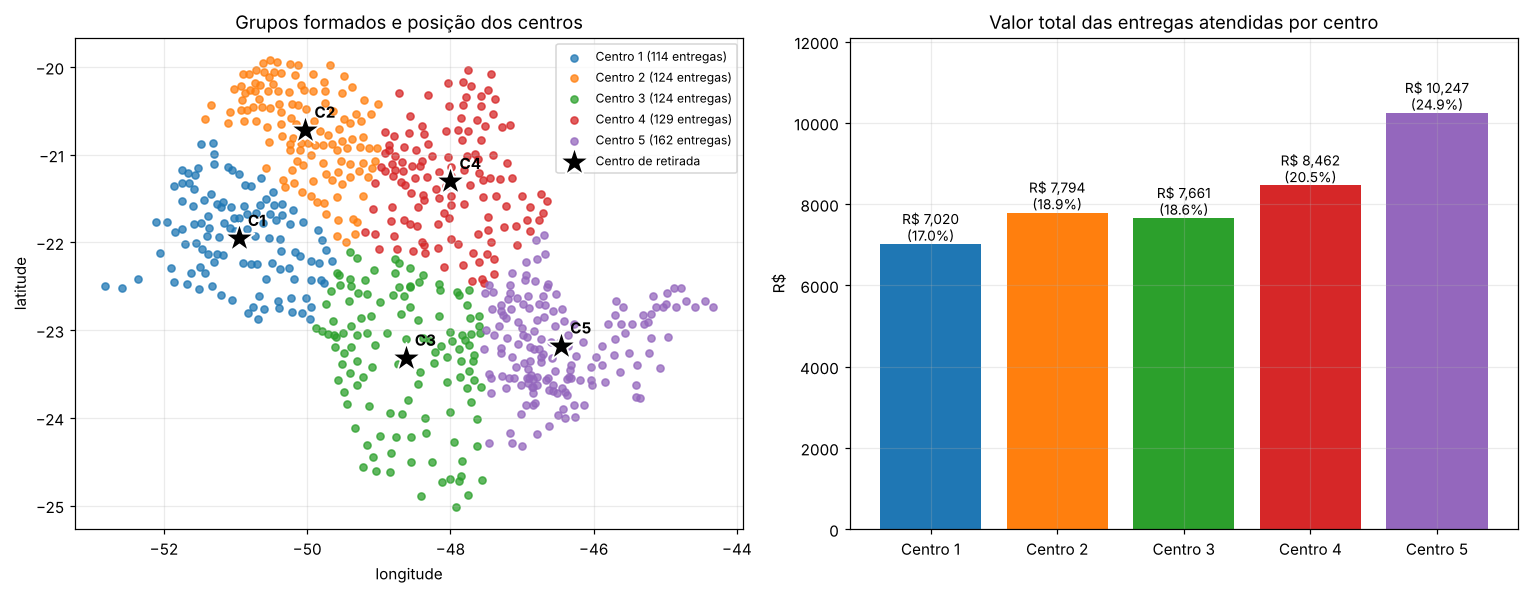

In [11]:
# Mapa dos grupos e valor atendido por centro
cores = plt.cm.tab10(np.arange(K))
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

for i, nome in enumerate(centros.index):
    pts = df[df.centro == nome]
    ax[0].scatter(pts.longitude, pts.latitude, s=22, color=cores[i], alpha=.75, label=f'{nome} ({len(pts)} entregas)')
ax[0].scatter(centros.longitude, centros.latitude, marker='*', s=420, c='black', edgecolor='white', lw=1.2, zorder=5, label='Centro de retirada')
for nome, r in centros.iterrows():
    ax[0].annotate(nome.replace('Centro ', 'C'), (r.longitude, r.latitude), xytext=(6, 8), textcoords='offset points',
                   fontsize=10, weight='bold')
ax[0].set(title='Grupos formados e posição dos centros', xlabel='longitude', ylabel='latitude')
ax[0].legend(fontsize=8, loc='best')

barras = ax[1].bar(tabela.index, tabela['valor total (R$)'], color=cores)
for b, v, p in zip(barras, tabela['valor total (R$)'], tabela['% do valor total']):
    ax[1].text(b.get_x() + b.get_width() / 2, v, f'R$ {v:,.0f}\n({p:.1f}%)', ha='center', va='bottom', fontsize=9)
ax[1].set(title='Valor total das entregas atendidas por centro', ylabel='R$')
ax[1].set_ylim(0, tabela['valor total (R$)'].max() * 1.18)
plt.tight_layout(); plt.show()

In [12]:
# Sensibilidade: e se a empresa optar por 4 ou 6 centros? (valor total por centro, em R$)
for k in (4, 5, 6):
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    v = df.assign(g=km.labels_).groupby('g')['price'].sum().sort_values(ascending=False)
    print(f'k = {k}: ' + ' | '.join(f'{x:,.0f}' for x in v.values) + f'   (soma = {v.sum():,.2f})')

k = 4: 12,838 | 11,068 | 9,440 | 7,837   (soma = 41,183.81)
k = 5: 10,247 | 8,462 | 7,794 | 7,661 | 7,020   (soma = 41,183.81)
k = 6: 10,292 | 8,071 | 7,678 | 6,228 | 6,062 | 2,854   (soma = 41,183.81)


## 5. Conclusão

**Resposta: 5 centros de retirada**, com o seguinte valor de entregas atendido por cada um (base: 653 entregas com falha, R$ 41.183,81):

| Centro | Nº de entregas | Valor total das entregas | % do valor |
|---|---:|---:|---:|
| Centro 1 | 114 | R$ 7.020,18 | 17,05% |
| Centro 2 | 124 | R$ 7.794,24 | 18,93% |
| Centro 3 | 124 | R$ 7.660,93 | 18,60% |
| Centro 4 | 129 | R$ 8.461,52 | 20,55% |
| Centro 5 | 162 | R$ 10.246,94 | 24,88% |
| **Total** | **653** | **R$ 41.183,81** | **100%** |

**Algoritmo escolhido: K-Means.** Ele sorteia k centros iniciais, associa cada entrega ao centro mais próximo, recalcula cada centro como a média das entregas do grupo e repete até estabilizar, minimizando a distância dos pontos ao centro do seu grupo. Rodamos 50 inicializações diferentes para evitar um resultado ruim por azar de sorteio, e fixamos a semente para o resultado ser reproduzível. Foi escolhido porque produz um centroide por grupo (a localização do centro), permite variar k e gerou os grupos mais compactos e equilibrados entre os algoritmos testados.

**A análise foi bem-sucedida?** Em boa parte, sim, com uma ressalva importante.
- **O que funcionou:** a resposta é clara, reprodutível e conferida (a soma dos valores dos 5 grupos é igual ao total da base, sem entrega perdida ou duplicada). Os centros ficaram equilibrados, o mais carregado concentra 24,9% do valor e o menos carregado 17,0%.
- **A ressalva:** os dados **não têm uma estrutura de agrupamento forte**. A silhueta de ~0,40 indica separação fraca a moderada, e os cenários de 4 a 6 centros são estatisticamente parecidos. Logo, "5" é uma escolha de equilíbrio entre estabilidade, cotovelo e carga por centro, e não um número que os dados "revelaram". Para comparação, com 4 centros o valor atendido seria R$ 12.838 / 11.068 / 9.440 / 7.837 e com 6 centros R$ 10.292 / 8.071 / 7.678 / 6.228 / 6.062 / 2.854 (um centro pequeno demais).

**Limitações e próximos passos**
- As coordenadas não são reais, então a posição dos centros é apenas ilustrativa; o resultado confiável é a **quantidade** de centros e a divisão do valor entre eles.
- O centroide é a posição média e não leva em conta o valor das entregas. Uma alternativa é ponderar o agrupamento pelo valor ou usar o ponto real mais central do grupo (medoide).
- Antes de decidir, vale repetir a análise com coordenadas reais e cruzar o resultado com o custo de instalação de cada box e com a economia esperada na última milha. Se a empresa preferir começar menor, o Centro 5 é o de maior retorno potencial (24,9% do valor).